In [1]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress, t
from arch.bootstrap import MovingBlockBootstrap

# 并行处理库
from multiprocessing import Pool, cpu_count

# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from matplotlib.ticker import PercentFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def draw_bracket(ax, x0, x1, y, h=0.0025, lw=1.2, color='k', text=None, text_offset=0.0008):
    """
    x0, x1: 括号覆盖的左右 x（数据坐标，和 bar 的 x_pos 一致）
    y: 括号底部 y（数据坐标）
    h: 括号竖线高度（向上）
    """
    ax.vlines([x0, x1], y, y-h, colors=color, linewidth=lw, clip_on=False)

    ax.hlines(y-h, x0, x1, colors=color, linewidth=lw, clip_on=False)
    if text is not None:
        ax.text((x0 + x1)/2, y-h-text_offset, text,
                ha='center', va='top', color=color, fontsize=11, clip_on=False)

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            if i > trend_select and i < (len_amp - trend_select - min_len):
                continue
            # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            if (j - i - min_len) > trend_select:
                continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    # 计算趋势差 diff
    if site == 'PTB':
        trend_start = heat_map[1, -trend_select:, -trend_select:]
        trend_end = heat_map[1, :trend_select, :trend_select]
    else:
        trend_start = heat_map[1, :trend_select, :trend_select]
        trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]


    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio
    else:
        return diff, sign, p_diff

def p_to_stars(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.05:
        return '**'
    elif p <= 0.1:
        return '*'
    else:
        return ''

def cal_area_grid(lat, lon, radius=6371000):
    lat_rad = np.radians(lat)
    lat_diff = np.diff(lat_rad) / 2  # 使用中间差值
    
    area = np.zeros((len(lat), len(lon)))
    
    lat_area_factors = radius ** 2 * np.abs(
        np.sin(lat_rad[:-1] + lat_diff) - np.sin(lat_rad[:-1] - lat_diff)
    )

    lon_diff = np.abs(np.radians(lon[1] - lon[0]))

    area[:-1, :] = lat_area_factors[:, np.newaxis] * lon_diff
    area[-1, :] = area[-2, :] 
    area[:, -1] = area[:, -2] 
    
    return area

def draw_vertical_annotation(ax, x, y_start, y_end, text, color='black', arrow_type='bar'):
    """
    在图上的指定 x 位置，从 y_start 到 y_end 画垂直标注线和文字。
    arrow_type: 'bar' (工字形) 或 'arrow' (双箭头)
    """
    mid_y = (y_start + y_end) / 2
    
    if arrow_type == 'bar':
        # 画工字形线 (|-|)
        # 竖线
        ax.plot([x, x], [y_start, y_end], color=color, linewidth=1, linestyle='-')
        # 上横杠
        ax.plot([x - 0.1, x + 0.1], [y_end, y_end], color=color, linewidth=1)
        # 下横杠
        ax.plot([x - 0.1, x + 0.1], [y_start, y_start], color=color, linewidth=1)
    
    elif arrow_type == 'arrow':
        # 使用 annotate 画双箭头
        ax.annotate('', xy=(x, y_start), xytext=(x, y_end),
                    arrowprops=dict(arrowstyle='<->', color=color, lw=1))
    
    # 添加文字 (稍微向左偏移一点，避免压线，并垂直居中)
    ax.text(x - 0.7, mid_y, text, ha='center', va='center', fontsize=10, color=color)

def cal_MBB_corr_contribusion(x, y, boot_times, block_len, x_num):
    """
    该函数用来使用Moving Block Bootstrapping方法计算序列对于
    例如先有两个序列y1和y2，其中y1 = x1+x2+x3 想要的到针对y1与y2之间相关中，不同变量x的贡献
    输入y为一维数据，x中每一行为不同变量的数据
    一般选择boot_times为1000
    block_len为12
    """
    x = np.transpose(x)
    y = np.transpose(y)
    bs = MovingBlockBootstrap(block_len, x, y = y)
    num = 0

    data_boot = np.zeros((x_num, boot_times))
    # bootstrap计算显著性区间 1 sigma
    for boot in bs.bootstrap(boot_times):
        bs_x = np.squeeze(boot[0][0])
        bs_y = boot[1]['y']

        ## 计算变量和的标准差
        bs_x_sum = np.sum(bs_x, axis=1)
        std_x_sum = np.std(bs_x_sum)

        for num_exp in range(x_num):
            x_temp = bs_x[:, num_exp]
            r = cal_pearson_corr(bs_y, x_temp)
            std_x = np.std(x_temp)

            data_boot[num_exp, num] = r * std_x / std_x_sum
            
        num = num+1

    params = np.full(x_num, np.nan)
    std_sum = np.std(np.sum(x, axis=1))
    for num_exp in range(x_num):
        params[num_exp] = cal_pearson_corr(y, x[:, num_exp]) * np.std(x[:, num_exp]) / std_sum
    param_std = np.std(data_boot, axis=1)
    
    return param_std, params

def cal_pearson_corr(y, x):
    # 确保 x 和 y 是 NumPy 数组
    y = np.array(y)
    x = np.array(x)

    # 去中心化
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    x_diff = x - x_mean
    y_diff = y - y_mean

    # 相关系数公式
    numerator = np.sum(x_diff * y_diff)
    denominator = np.sqrt(np.sum(x_diff**2) * np.sum(y_diff**2))

    r = numerator / denominator
    return r

In [2]:
# 读取Boreal数据
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-Trendy/'
files = os.listdir(folder)
model_dict = {}
exp_list = ['control', 'CFE', 'CLIM', 'LULCC']

for file in files:
    model = file.split('.')[0]
    if model == 'VISIT':
        continue
    if model == 'CLM5':
        model = 'CLM5.0'
    with xr.open_dataset(os.path.join(folder, file)) as ds:
        amp_region_temp = ds['amp_cum_region'].values
        amp_region = np.zeros_like(amp_region_temp)
        amp_region[0] = amp_region_temp[-1]                      # Control
        amp_region[1] = amp_region_temp[1]                       # CFE
        amp_region[2] = amp_region_temp[2] - amp_region_temp[1]  # Climate
        amp_region[3] = amp_region_temp[3] - amp_region_temp[2]  # LULCC
        model_dict[model] = {
            'amp_boreal': amp_region,
            'time': ds['time'].values,
        }

# 读取Temperate land累积碳AMP
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Trendy-Temperate-land-amp-cum-region/'
exp_origin_list = ['S0', 'S1', 'S2', 'S3']

for model in model_dict.keys():
    amp_cum = []
    if model == 'Trendy':
        continue
    for exp in exp_origin_list:
        file = os.listdir(os.path.join(folder, exp, model))[0]
        file_path = os.path.join(folder, exp, model, file)
        ds = xr.open_dataset(file_path)
        amp_cum.append(ds['amp_cum'].values[-1])
    amp_cum = np.array(amp_cum)
    amp_cum_temp = np.zeros_like(amp_cum)
    amp_cum_temp[0] = amp_cum[-1]
    amp_cum_temp[1] = amp_cum[1]
    amp_cum_temp[2] = amp_cum[2] - amp_cum[1]
    amp_cum_temp[3] = amp_cum[3] - amp_cum[2] 
    # 截取1980-2021
    model_dict[model]['amp_temp'] = amp_cum_temp

## 计算Trendy集合
amp_cum_trendy = []
amp_wind_trendy = []
for model in model_dict.keys():
    if model == 'Trendy':
        continue
    amp_cum_trendy.append(model_dict[model]['amp_temp'])

amp_cum_trendy = np.array(amp_cum_trendy).mean(axis=0)
model_dict['Trendy']['amp_temp'] = amp_cum_trendy

# 计算trend diff
min_line = 20
trend_select = 7
count_diff = np.sum(np.arange(1, trend_select + 1))

for model, info in model_dict.items():
    time = info['time']
    amp_boreal = info['amp_boreal']
    amp_temp = info['amp_temp']
    amp = np.array([amp_boreal, amp_temp])

    diff = np.full((2, len(exp_list), count_diff), np.nan) # 2是boreal和temperate，count_diff是趋势差的数量
    sign = np.full((2, len(exp_list)), np.nan)
    p_value = np.full((2, len(exp_list)), np.nan)

    for i in range(2):
        for j in range(len(exp_list)):
            diff[i, j, :], sign[i, j], p_value[i, j] = cal_trend_diff(
                amp[i, j], time, min_line, trend_select
            )
    
    model_dict[model]['diff'] = diff
    model_dict[model]['sign'] = sign
    model_dict[model]['p_value'] = p_value

In [3]:
# print trendy各个因子acc的贡献和量值
exp_list = ['control', 'CFE', 'CLIM', 'LULCC']
region_names = ['Boreal', 'Temperate']

print('=' * 70)
print('Trendy 各因子加速贡献和量值')
print('=' * 70)

td = model_dict['Trendy']

for r, region in enumerate(region_names):
    ctrl = td['diff'][r, 0, :].mean()
    print(f'\n{region}:')
    print(f"  {'Factor':<10s} {'PgC yr⁻¹':>10s}  {'TgC yr⁻¹':>10s}  {'Contribution':>14s}  {'p-value':>10s}")
    print(f"  {'-'*65}")
    for e, exp in enumerate(exp_list):
        m = td['diff'][r, e, :].mean()
        ratio = m / ctrl * 100
        pv = td['p_value'][r, e]
        print(f"  {exp:<10s} {m:>+8.4f}     {m*1000:>+8.2f}     {ratio:>+10.1f} %     {pv:>8.4f} {p_to_stars(pv)}")

# 各因子对两个区域的总贡献 (Boreal + Temperate 合计)
print(f"\n{'=' * 70}")
print('各因子 Boreal + Temperate 合计')
print('=' * 70)
boreal_ctrl = td['diff'][0, 0, :].mean()
print(f"  {'Factor':<10s} {'PgC yr⁻¹':>10s}  {'TgC yr⁻¹':>10s}  {'% of Control':>14s}")
print(f"  {'-'*50}")
for e, exp in enumerate(exp_list):
    total = td['diff'][0, e, :].mean() + td['diff'][1, e, :].mean()
    print(f"  {exp:<10s} {total:>+8.4f}     {total*1000:>+8.2f}     {total/boreal_ctrl*100:>+10.1f} %")

Trendy 各因子加速贡献和量值

Boreal:
  Factor       PgC yr⁻¹    TgC yr⁻¹    Contribution     p-value
  -----------------------------------------------------------------
  control     +0.0032        +3.16         +100.0 %       0.0000 ***
  CFE         +0.0055        +5.55         +175.9 %       0.0000 ***
  CLIM        -0.0032        -3.19         -101.2 %       0.0000 ***
  LULCC       +0.0008        +0.80          +25.3 %       0.0000 ***

Temperate:
  Factor       PgC yr⁻¹    TgC yr⁻¹    Contribution     p-value
  -----------------------------------------------------------------
  control     +0.0021        +2.09         +100.0 %       0.0000 ***
  CFE         +0.0027        +2.74         +131.0 %       0.0000 ***
  CLIM        +0.0013        +1.31          +62.4 %       0.0027 **
  LULCC       -0.0020        -1.96          -93.4 %       0.0000 ***

各因子 Boreal + Temperate 合计
  Factor       PgC yr⁻¹    TgC yr⁻¹    % of Control
  --------------------------------------------------
  control     

In [4]:
# Part3 统一land和wind
folder_boreal = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Trendy-GC-amp-Boreal-mask/'
folder_temperate = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Trendy-GC-amp-Temperate-mask/'
files = os.listdir(folder_boreal)
Part3_dict = {}
exp_list = ['control', 'land', 'CFE', 'CLIM', 'LULCC', 'wind']
min_len = 20
trend_select = 7
count_diff = np.sum(np.arange(1, trend_select + 1))
n_exp = len(exp_list)

for file in files:
    model = file.split('-')[0]

    ds_b = xr.open_dataset(os.path.join(folder_boreal, file))
    ds_t = xr.open_dataset(os.path.join(folder_temperate, file))

    # (mask region, exp, time)
    amp_region = np.array([ds_b['amp_region'].values, ds_t['amp_region'].values])
    residual = amp_region[0, -1] - amp_region[1, -1]
    amp_region[1, -1] += residual

    # (mask region, exp)
    trend_diff = np.full((2, n_exp, count_diff), np.nan)
    sign_diff = np.full((2, n_exp), np.nan)
    p_diff = np.full((2, n_exp), np.nan)

    for r in range(2):
        for e in range(n_exp):
            diff, sign, p_val = cal_trend_diff(amp_region[r, e, :], ds_b['time'].values, min_len, trend_select)
            trend_diff[r, e, :] = diff
            sign_diff[r, e] = sign
            p_diff[r, e] = p_val

    Part3_dict[model] = {
        'trend_diff': trend_diff,
        'sign_diff': sign_diff,
        'p_diff': p_diff
    }
    if model != 'Trendy':
        continue
    print(f'Processed model: {model}')
    for e in range(n_exp):
        print(f'''  Experiment: {exp_list[e]}
              Boreal: {trend_diff[0, e, :].mean():.4f} PPM/yr  {trend_diff[0, e, :].mean() / trend_diff[0, 0, :].mean()}%
              Temp: {trend_diff[1, e, :].mean():.4f}  {trend_diff[1, e, :].mean() / trend_diff[0, 0, :].mean()}%''')

Processed model: Trendy
  Experiment: control
              Boreal: 0.0507 PPM/yr  1.0%
              Temp: 0.0507  1.000000000000005%
  Experiment: land
              Boreal: 0.0277 PPM/yr  0.5468478978068319%
              Temp: 0.0207  0.4086543092609102%
  Experiment: CFE
              Boreal: 0.0179 PPM/yr  0.3529888127317379%
              Temp: 0.0140  0.27574116484828237%
  Experiment: CLIM
              Boreal: 0.0079 PPM/yr  0.1567630416521461%
              Temp: 0.0056  0.1114032275457606%
  Experiment: LULCC
              Boreal: 0.0019 PPM/yr  0.0370960434229474%
              Temp: 0.0011  0.02150991686686732%
  Experiment: wind
              Boreal: 0.0230 PPM/yr  0.45315210219316704%
              Temp: 0.0230  0.45315210219316704%


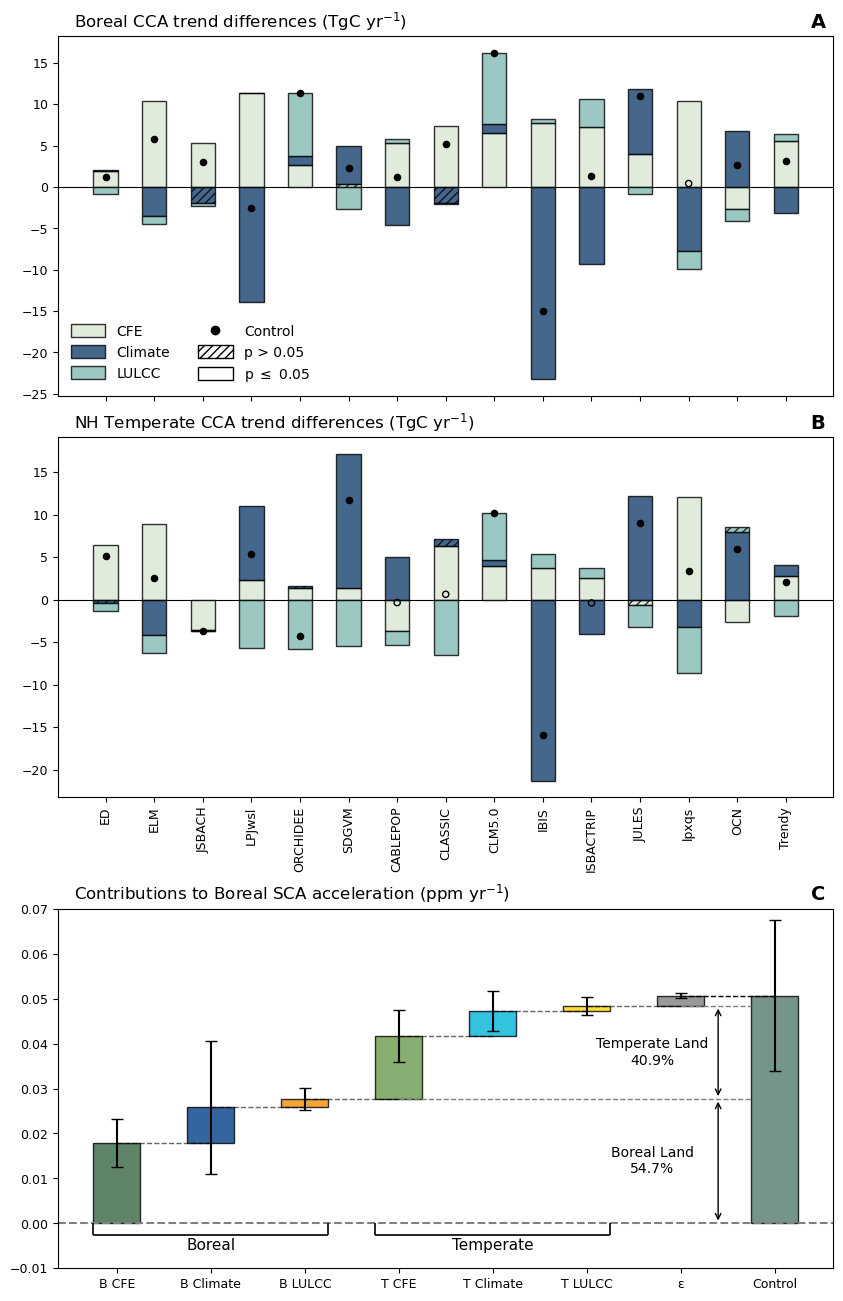

In [6]:
# 画图
gs = gridspec.GridSpec(4, 1, height_ratios=[1, 1, 0.08, 1], hspace=0.15)
fig = plt.figure(figsize=(10, 16))
axs = np.empty((3), dtype=object)
axs[0] = fig.add_subplot(gs[0])
axs[1] = fig.add_subplot(gs[1])
axs[2] = fig.add_subplot(gs[-1])

# region Part1
colors = ['#dae6d3', '#16416e', '#83bbb4']
exp_list = ['control', 'CFE', 'CLIM', 'LULCC']
model_keys = list(model_dict.keys())
n_models = len(model_keys)
n_exp = len(exp_list)

for n_r in range(2):
    ax = axs[n_r]

    bar_mean = np.zeros((n_exp, n_models))
    bar_std = np.zeros((n_exp, n_models))
    p_vals = np.ones((n_exp, n_models))
    sig_vals = np.ones((n_exp, n_models))

    for n_m, (model, info) in enumerate(model_dict.items()):
        diff = info['diff'][n_r]
        sign = info['sign'][n_r]
        p_value = info['p_value'][n_r]

        bar_mean[:, n_m] = diff.mean(axis=-1)
        bar_std[:, n_m] = diff.std(axis=-1)
        p_vals[:, n_m] = p_value
        sig_vals[:, n_m] = sign
    
    x_data = np.arange(n_models)
    bottom_pos = np.zeros(n_models)
    bottom_neg = np.zeros(n_models)

    for n_e, exp in enumerate(exp_list[1:]):
        y_data = bar_mean[n_e+1]
        y_err = bar_std[n_e+1]
        p_data = p_vals[n_e+1]
        y_data = y_data * 1000 # 转换为 TgC yr^-1
        
        # 根据 y 值的正负选择对应的底线
        bottom = np.where(y_data > 0, bottom_pos, bottom_neg)
        
        bars = ax.bar(x_data, y_data, bottom=bottom, label=exp, 
                    color=colors[n_e], width=0.5,
                    edgecolor='black', linewidth=1, alpha=0.8)

        for idx, rect in enumerate(bars):
            if p_data[idx] > 0.1:
                rect.set_hatch('////')

        # 更新底线
        bottom_pos += np.maximum(y_data, 0)
        bottom_neg += np.minimum(y_data, 0)
    ax.axhline(0, color='black', linewidth=0.8, zorder=0)
    # 提取 control 组 (index 0) 的数据和 p 值
    y_control = bar_mean[0] * 1000
    p_control = p_vals[0]
    sig_mask = p_control <= 0.1
    nosig_mask = p_control > 0.1
    ax.scatter(x_data[sig_mask], y_control[sig_mask], color='black', marker='o', s=20, zorder=5)
    ax.scatter(x_data[nosig_mask], y_control[nosig_mask], facecolors='none', edgecolors='black', marker='o', s=20, zorder=5)

custom_lines = [
    mpatches.Patch(facecolor=colors[i], edgecolor='black', linewidth=1, alpha=0.8) 
    for i in range(len(exp_list)-1)
]
custom_lines.append(Line2D([0], [0], marker='o', color='black', markerfacecolor='black', markersize=6, lw=0, label='Control'))
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', hatch='////', linewidth=1))
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', linewidth=1))
labels_legend = ['CFE', 'Climate', 'LULCC', 'Control', 'p > 0.05', 'p $\leq$ 0.05']
axs[0].legend(custom_lines, labels_legend, 
          loc='lower left', frameon=False, fontsize=10,
          handlelength=2.5, handleheight=1., ncols=2)

titles = ['Boreal CCA trend differences (TgC yr$^{-1}$)', 'NH Temperate CCA trend differences (TgC yr$^{-1}$)']
for i in range(2):
    ax = axs[i]
    ax.set_xticks(x_data)
    if i == 0:
        ax.set_xticklabels([])
    else:
        ax.set_xticklabels(model_keys, rotation=90, ha='center', fontsize=10)
    ax.text(0.02, 1.01, titles[i], transform=ax.transAxes, ha='left', va='bottom', 
            fontsize=12)
# endregion

# region Part2
ax = axs[2]
trend_diff = Part3_dict['Trendy']['trend_diff']
components = [
    ('B CFE',   0, 2),
    ('B Clim',  0, 3),
    ('B LULCC', 0, 4),
    ('T CFE',   1, 2),
    ('T Clim',  1, 3),
    ('T LULCC', 1, 4),
]
data_value, data_std = [], []

for _, r, c in components:
    x = trend_diff[r, c, :]
    data_value.append(x.mean())
    data_std.append(x.std())

# epsilon
eps = trend_diff[0, 0, :] - trend_diff[0, 2:5, :].sum(axis=0) - trend_diff[1, 2:5, :].sum(axis=0)
data_value.append(eps.mean())
data_std.append(eps.std())

# control
ctrl = trend_diff[0, 0, :]
data_value.append(ctrl.mean())
data_std.append(ctrl.std())

data_value = np.asarray(data_value)
data_std   = np.asarray(data_std)

ax = axs[-1] 
label_list = [
    'B CFE',         
    'B Climate',        
    'B LULCC',       
    'T CFE',         
    'T Climate',        
    'T LULCC',       
    '\u03B5',       
    'Control'        
]

color_list = [
    '#386641', # B CFE 
    '#023e8a', # B Clim 
    '#f48c06', # B LULCC
    '#6a994e', # T CFE 
    '#00b4d8', # T Clim 
    '#ffd60a', # T LULCC 
    '#808080',  # Epsilon 
    '#52796f' # Control
]

# 计算累积瀑布图的 Bottom 和 Height
num_bars = len(data_value)
x_pos = np.arange(num_bars)

plot_bottoms = np.zeros(num_bars)
plot_heights = np.zeros(num_bars)

# 初始化累积水位 (Running Sum)
current_level = 0

# 遍历前 N-1 个元素 (Components)
for i in range(num_bars - 1):
    val = data_value[i]
    
    # 如果 val 是正数，柱子从 current_level 向上长
    # 如果 val 是负数，柱子从 current_level 向下长
    
    if val >= 0:
        plot_bottoms[i] = current_level
        plot_heights[i] = val
        current_level += val # 水位上升
    else:
        plot_bottoms[i] = current_level + val 
        plot_heights[i] = abs(val) 
        current_level += val # 水位下降 

# 处理最后一个元素 (Control)
plot_bottoms[-1] = 0
plot_heights[-1] = data_value[-1] # 直接使用 Control 的值

# 柱状图
bars = ax.bar(x_pos, plot_heights, bottom=plot_bottoms, 
              color=color_list, edgecolor='black', width=0.5,
              yerr=data_std, capsize=4, alpha=0.8)

# 连接阶梯线 
for i in range(num_bars - 2): 

    val = data_value[i]
    end_level = plot_bottoms[i] + plot_heights[i] if val >= 0 else plot_bottoms[i]
    
    next_x = x_pos[i+1]
    ax.plot([x_pos[i], x_pos[i+1]], [end_level, end_level], 
            color='black', linestyle='--', linewidth=1, alpha=0.6)

# 连接 Epsilon (倒数第二个) 到 Control (最后一个)
last_comp_idx = num_bars - 2
val = data_value[last_comp_idx]
end_level = plot_bottoms[last_comp_idx] + plot_heights[last_comp_idx] if val >= 0 else plot_bottoms[last_comp_idx]
ax.plot([x_pos[last_comp_idx], x_pos[-1]], [end_level, end_level], 
        color='black', linestyle='--', linewidth=1)

# 美化图表
ax.set_ylim(-0.01, 0.07)
ax.axhline(0, color='grey', linewidth=1.5, linestyle='--') 
ax.set_xticks(x_pos)
ax.set_xticklabels(label_list, fontsize=10)
ax.text(0.02, 1.01, 'Contributions to Boreal SCA acceleration (ppm yr$^{-1}$)', 
        transform=ax.transAxes, ha='left', va='bottom', fontsize=12)

# B: 覆盖 x_pos[0]~x_pos[2]（B CFE, B Clim, B LULCC）
draw_bracket(ax, x_pos[0] - 0.25, x_pos[2] + 0.25, y=0, text='Boreal')
# T: 覆盖 x_pos[3]~x_pos[5]（T CFE, T Clim, T LULCC）
draw_bracket(ax, x_pos[3] - 0.25, x_pos[5] + 0.25, y=0, text='Temperate')

# 标注land和wind
y_boreal_end = plot_bottoms[3] 
y_temperate_end = plot_bottoms[6]
y_total_end = plot_heights[-1]
ax.hlines(y_boreal_end, x_pos[3], x_pos[-1]-0.25, colors='grey', linewidth=1, linestyles='--')
ax.hlines(y_temperate_end, x_pos[6], x_pos[-1]-0.25, colors='grey', linewidth=1, linestyles='--')
anno_x = x_pos[-1] - 0.6
land_p = data_value[:3].sum() / data_value[-1]
wind_p = data_value[3:6].sum() / data_value[-1]
draw_vertical_annotation(ax, anno_x, 0, plot_bottoms[3], 
                         text='Boreal Land\n{:.1f}%'.format(land_p*100),
                         arrow_type='arrow')
draw_vertical_annotation(ax, anno_x, plot_bottoms[3], plot_bottoms[6], 
                         text='Temperate Land\n{:.1f}%'.format(wind_p*100), 
                         arrow_type='arrow')
# endregion

letters = list('ABCD')
for i, ax in enumerate(axs.flat):
    ax.text(0.99, 1.04, f'{letters[i]}', transform=ax.transAxes, 
            ha='right', va='center', fontsize=14, fontweight='bold')
    ax.tick_params(axis='both', which='major', labelsize=9)
fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/main-text-fig/Fig4.png', dpi=400,
            bbox_inches='tight', pad_inches=0.1)